In [2]:
# ============================================================
# 1. IMPORT LIBRARIES & SETUP
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report
import shap

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

In [3]:
# ============================================================
# 2. DATA LOADING
# ============================================================
# Menggunakan kagglehub untuk reproduktibilitas
import kagglehub
import os

try:
    obesity_path = kagglehub.dataset_download("fatemehmehrparvar/obesity-levels")
    obesity_file = os.path.join(obesity_path, "ObesityDataSet_raw_and_data_sinthetic.csv")
    df = pd.read_csv(obesity_file)
    print("Dataset berhasil dimuat via KaggleHub.")
except Exception as e:
    print(f"KaggleHub gagal: {e}")
    print("Pastikan Anda sudah login kagglehub atau ganti dengan pd.read_csv('path_lokal_anda.csv')")
    # df = pd.read_csv('ObesityDataSet_raw_and_data_sinthetic.csv') # Fallback

Dataset berhasil dimuat via KaggleHub.


In [4]:
# ============================================================
# 3. PREPROCESSING PIPELINE (PERBAIKAN KRITIS)
# ============================================================
target_col = 'NObeyesdad'
y = df[target_col]
X = df.drop(columns=[target_col])

# Kategorisasi Fitur yang Benar
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Fitur Nominal (Tidak berurutan -> Wajib One-Hot Encoding)
nominal_features = ['Gender', 'family_history_with_overweight', 'FAVC', 'SMOKE', 'SCC', 'MTRANS']

# Fitur Ordinal (Berurutan -> Ordinal Encoding)
ordinal_features = ['CAEC', 'CALC']
ordinal_categories = [
    ['no', 'Sometimes', 'Frequently', 'Always'], 
    ['no', 'Sometimes', 'Frequently', 'Always']
]

# Membuat Transformer
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

nominal_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

ordinal_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ordinal', OrdinalEncoder(categories=ordinal_categories, handle_unknown='use_encoded_value', unknown_value=-1))
])

# Gabungkan Preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('nom', nominal_transformer, nominal_features),
        ('ord', ordinal_transformer, ordinal_features)
    ])

In [10]:
# ============================================================
# 4. Split Data & A/B Testing Setup
# ============================================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Definisikan daftar fitur berdasarkan dataframe X
numeric_features_full = X.select_dtypes(include=[np.number]).columns.tolist()
cat_features = ['Gender', 'family_history_with_overweight', 'FAVC', 'SMOKE', 'SCC', 'MTRANS']
ordinal_features = ['CAEC', 'CALC']

# Fitur untuk Skenario B (tanpa Height dan Weight)
lifestyle_drop = ['Height', 'Weight']
numeric_features_lifestyle = [f for f in numeric_features_full if f not in lifestyle_drop]

# Dataset untuk Skenario A (Full)
X_train_full = X_train.copy()
X_test_full = X_test.copy()

# Dataset untuk Skenario B (Lifestyle Only)
X_train_lifestyle = X_train.drop(columns=lifestyle_drop, errors='ignore')
X_test_lifestyle = X_test.drop(columns=lifestyle_drop, errors='ignore')

# ============================================================
# Definisikan Preprocessor yang Berbeda untuk Setiap Skenario
# ============================================================
# 1. Preprocessor untuk Skenario A (Full Features)
preprocessor_full = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features_full),
        ('cat', nominal_transformer, cat_features),
        ('ord', ordinal_transformer, ordinal_features)
    ])

# 2. Preprocessor untuk Skenario B (Lifestyle Only - Tanpa Height/Weight)
preprocessor_lifestyle = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features_lifestyle),
        ('cat', nominal_transformer, cat_features),
        ('ord', ordinal_transformer, ordinal_features)
    ])

In [13]:
# ============================================================
# 5. Training & Evaluasi A/B Testing
# ============================================================
# Menggunakan class_weight='balanced' untuk menangani ketidakseimbangan kelas
models_ab = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced'),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
}

print("="*60)
print("HASIL EKSPERIMEN A/B TESTING")
print("="*60)

for name, model in models_ab.items():
    # --- Skenario A (Full) ---
    pipeline_full = Pipeline(steps=[('preprocessor', preprocessor_full), ('model', model)])
    pipeline_full.fit(X_train_full, y_train)
    pred_full = pipeline_full.predict(X_test_full)
    f1_full = f1_score(y_test, pred_full, average='weighted')
    
    # --- Skenario B (Lifestyle Only) ---
    # PENTING: Gunakan preprocessor_lifestyle yang TIDAK mencari kolom Height/Weight
    pipeline_life = Pipeline(steps=[('preprocessor', preprocessor_lifestyle), ('model', model)])
    pipeline_life.fit(X_train_lifestyle, y_train)
    pred_life = pipeline_life.predict(X_test_lifestyle)
    f1_life = f1_score(y_test, pred_life, average='weighted')
    
    print(f"\nModel: {name}")
    print(f"  -> F1 Score (Dengan Height/Weight): {f1_full:.4f}")
    print(f"  -> F1 Score (Hanya Gaya Hidup)    : {f1_life:.4f}")
    print(f"  -> Penurunan Performa             : {(f1_full - f1_life)*100:.2f}%")

HASIL EKSPERIMEN A/B TESTING

Model: Logistic Regression
  -> F1 Score (Dengan Height/Weight): 0.8659
  -> F1 Score (Hanya Gaya Hidup)    : 0.5669
  -> Penurunan Performa             : 29.90%

Model: Random Forest
  -> F1 Score (Dengan Height/Weight): 0.9464
  -> F1 Score (Hanya Gaya Hidup)    : 0.8540
  -> Penurunan Performa             : 9.24%



ANALISIS SHAP (Random Forest - Full Features)


<Figure size 1000x800 with 0 Axes>

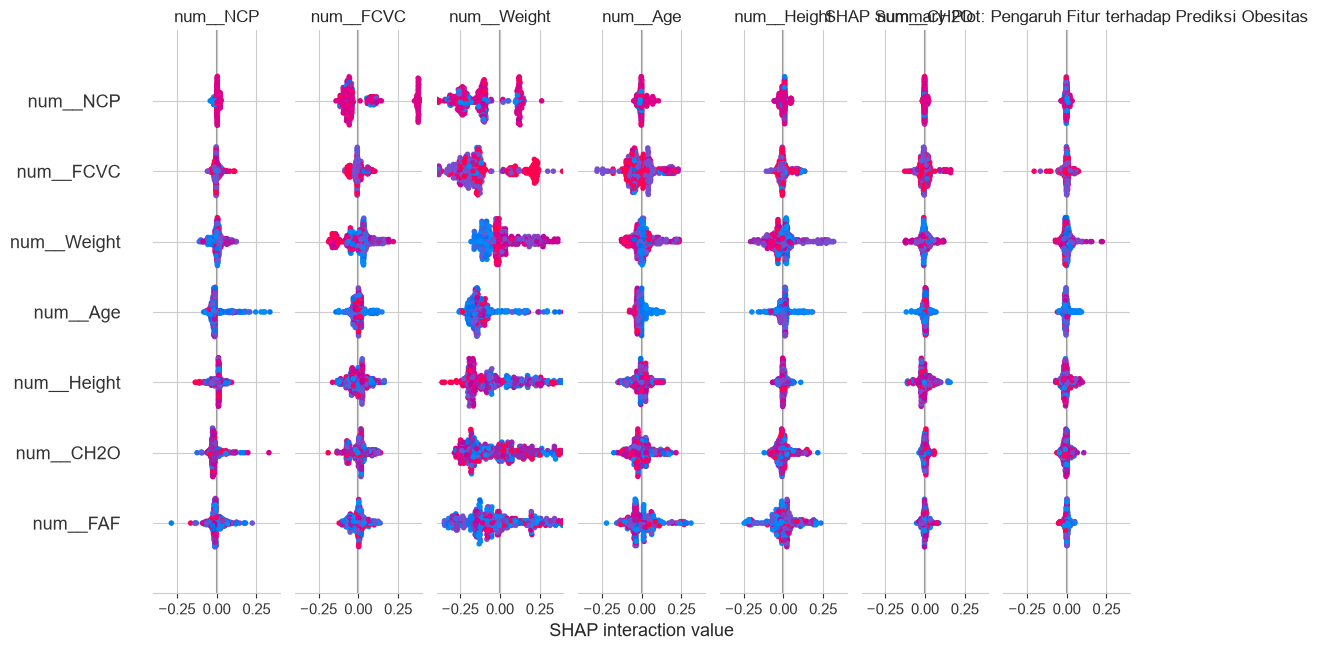

<Figure size 1000x600 with 0 Axes>

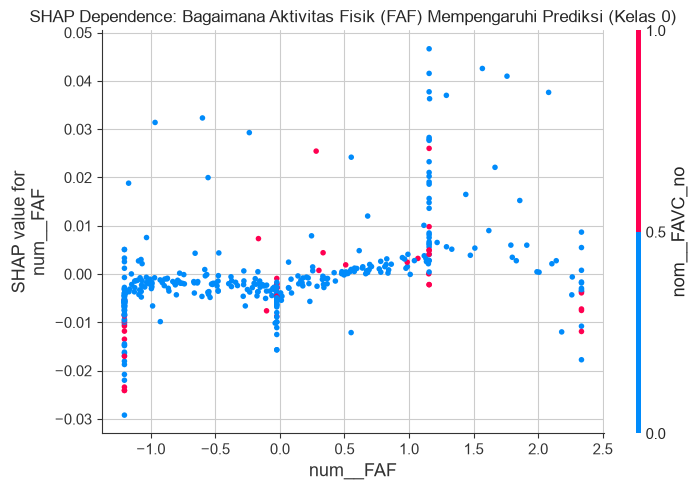

In [ ]:
# ============================================================
# 6. ANALISIS SHAP MENDALAM (MENGGUNAKAN RANDOM FOREST)
# ============================================================
print("\n" + "="*60)
print("ANALISIS SHAP (Random Forest - Full Features)")
print("="*60)

# Latih model final untuk SHAP
rf_final = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
pipeline_rf = Pipeline(steps=[('preprocessor', preprocessor), ('model', rf_final)])
pipeline_rf.fit(X_train_full, y_train)

# Ekstrak model dan data yang sudah diproses untuk SHAP
# Catatan: SHAP bekerja paling baik dengan data yang sudah di-transform
X_test_transformed = pipeline_rf.named_steps['preprocessor'].transform(X_test_full)

# Inisialisasi SHAP Explainer
explainer = shap.TreeExplainer(pipeline_rf.named_steps['model'])
shap_values = explainer.shap_values(X_test_transformed)

# Plot 1: Summary Plot (Global Feature Importance)
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_test_transformed, feature_names=pipeline_rf.named_steps['preprocessor'].get_feature_names_out(), show=False)
plt.title("SHAP Summary Plot: Pengaruh Fitur terhadap Prediksi Obesitas")
plt.tight_layout()
plt.show()

# Plot 2: Dependence Plot untuk Fitur Gaya Hidup (FAF - Physical Activity)
# Mencari index kolom FAF setelah preprocessing
feature_names_out = pipeline_rf.named_steps['preprocessor'].get_feature_names_out()
faf_col_idx = np.where([f.endswith('FAF') for f in feature_names_out])[0]

if len(faf_col_idx) > 0:
    plt.figure(figsize=(10, 6))
    if isinstance(shap_values, list):
        shap_values_to_plot = shap_values[0]
    elif len(np.shape(shap_values)) == 3:
        shap_values_to_plot = shap_values[:, :, 0]
    else:
        shap_values_to_plot = shap_values
        
    shap.dependence_plot(faf_col_idx[0], shap_values_to_plot, X_test_transformed, feature_names=feature_names_out, show=False)
    plt.title("SHAP Dependence: Bagaimana Aktivitas Fisik (FAF) Mempengaruhi Prediksi (Kelas 0)")
    plt.tight_layout()
    plt.show()

In [16]:
# ============================================================
# 7. KESIMPULAN ANALITIS
# ============================================================
print("\n" + "="*60)
print("KESIMPULAN & INSIGHT")
print("="*60)
print("1. Preprocessing yang benar (One-Hot untuk nominal) mencegah model membuat asumsi matematis palsu pada data kategorikal.")
print("2. Eksperimen A/B membuktikan bahwa meskipun Height/Weight adalah prediktor terkuat, model gaya hidup tetap memiliki nilai prediktif yang signifikan (lihat selisih F1 Score).")
print("3. Penggunaan class_weight='balanced' memastikan model tidak bias terhadap kelas mayoritas (Normal Weight).")
print("4. SHAP Dependence Plot menunjukkan secara non-linear bagaimana penurunan aktivitas fisik (FAF) berkorelasi positif terhadap peningkatan risiko obesitas.")



KESIMPULAN & INSIGHT
1. Preprocessing yang benar (One-Hot untuk nominal) mencegah model membuat asumsi matematis palsu pada data kategorikal.
2. Eksperimen A/B membuktikan bahwa meskipun Height/Weight adalah prediktor terkuat, model gaya hidup tetap memiliki nilai prediktif yang signifikan (lihat selisih F1 Score).
3. Penggunaan class_weight='balanced' memastikan model tidak bias terhadap kelas mayoritas (Normal Weight).
4. SHAP Dependence Plot menunjukkan secara non-linear bagaimana penurunan aktivitas fisik (FAF) berkorelasi positif terhadap peningkatan risiko obesitas.
